In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


df = sns.load_dataset("taxis")


df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [2]:

df.isnull().sum()

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[us]
 1   dropoff          6433 non-null   datetime64[us]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   str           
 9   payment          6389 non-null   str           
 10  pickup_zone      6407 non-null   str           
 11  dropoff_zone     6388 non-null   str           
 12  pickup_borough   6407 non-null   str           
 13  dropoff_borough  6388 non-null   str           
dtypes: datetime64[us](2), float64(5), int64(1), str(6)


In [4]:
df.shape

(6433, 14)

In [5]:
df.columns

Index(['pickup', 'dropoff', 'passengers', 'distance', 'fare', 'tip', 'tolls',
       'total', 'color', 'payment', 'pickup_zone', 'dropoff_zone',
       'pickup_borough', 'dropoff_borough'],
      dtype='str')

In [6]:
df.isnull().sum()

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

In [7]:
df.select_dtypes(include='number').columns|

SyntaxError: invalid syntax (2347247877.py, line 1)

In [8]:
df.select_dtypes(include='number').columns

Index(['passengers', 'distance', 'fare', 'tip', 'tolls', 'total'], dtype='str')

In [9]:
df.select_dtypes(include='object').columns

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_28616\3732952691.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes(include='object').columns


Index(['color', 'payment', 'pickup_zone', 'dropoff_zone', 'pickup_borough',
       'dropoff_borough'],
      dtype='str')

In [10]:
df.select_dtypes(include='object').columns

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_28616\3732952691.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes(include='object').columns


Index(['color', 'payment', 'pickup_zone', 'dropoff_zone', 'pickup_borough',
       'dropoff_borough'],
      dtype='str')

In [11]:
# Fill missing values

df['payment'] = df['payment'].fillna(df['payment'].mode()[0])

df['pickup_zone'] = df['pickup_zone'].fillna(df['pickup_zone'].mode()[0])

df['dropoff_zone'] = df['dropoff_zone'].fillna(df['dropoff_zone'].mode()[0])

df['pickup_borough'] = df['pickup_borough'].fillna(df['pickup_borough'].mode()[0])

df['dropoff_borough'] = df['dropoff_borough'].fillna(df['dropoff_borough'].mode()[0])

In [12]:
df.isnull().sum()

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64

In [13]:


df['pickup'] = pd.to_datetime(df['pickup'])

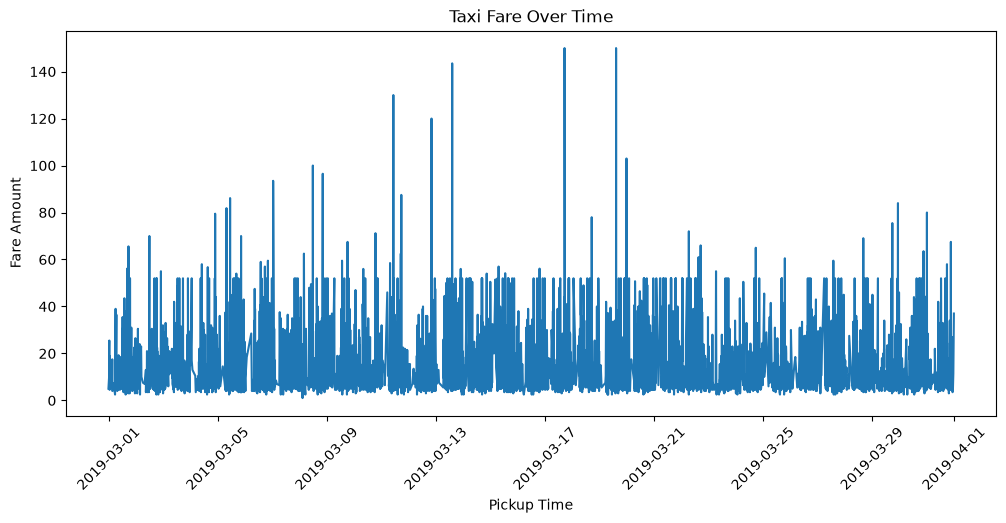

In [14]:
# Sort data by pickup time
df = df.sort_values('pickup')

# Create line chart
plt.figure(figsize=(12, 5))

plt.plot(df['pickup'], df['fare'])

plt.title('Taxi Fare Over Time')
plt.xlabel('Pickup Time')
plt.ylabel('Fare Amount')

plt.xticks(rotation=45)
plt.show()

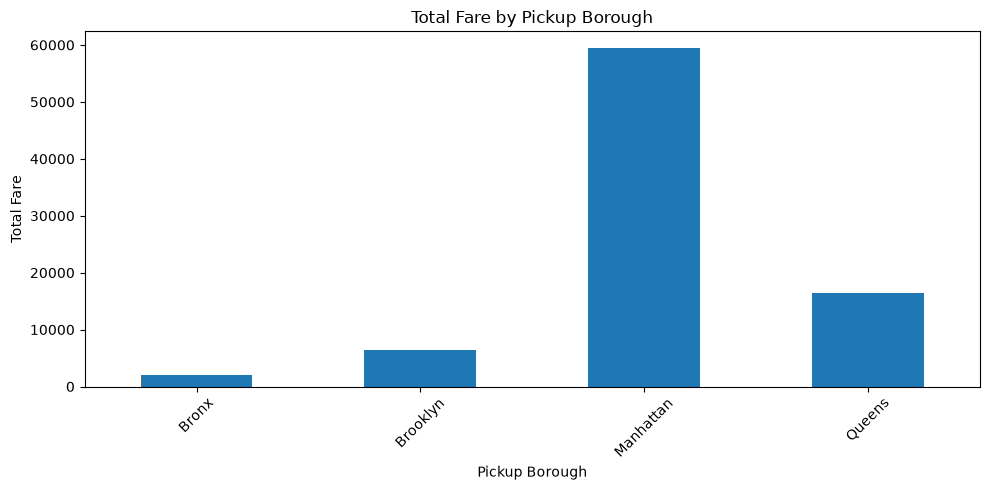

In [15]:
# Create bar chart
borough_fare = df.groupby('pickup_borough')['fare'].sum()

plt.figure(figsize=(10, 5))

borough_fare.plot(kind='bar')

plt.title('Total Fare by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Total Fare')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

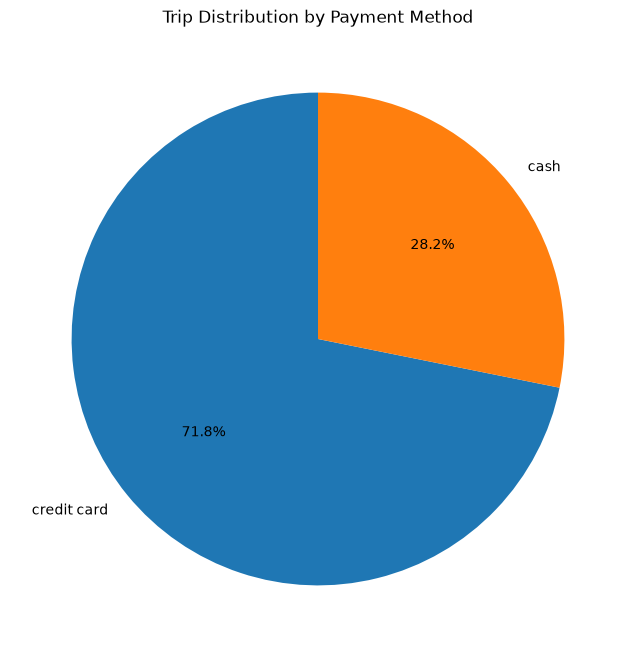

In [16]:
# Create pie chart
payment_counts = df['payment'].value_counts()


plt.figure(figsize=(8, 8))

plt.pie(payment_counts,
        labels=payment_counts.index,
        autopct='%1.1f%%',
        startangle=90)

plt.title('Trip Distribution by Payment Method')

plt.show()

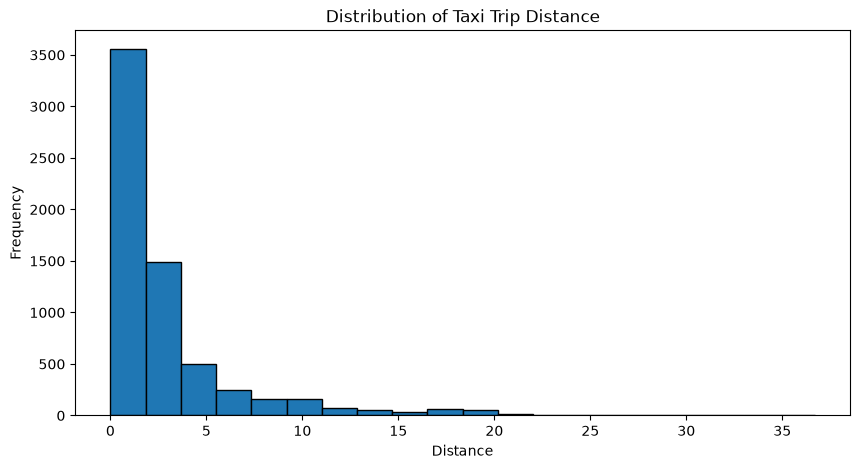

In [17]:
plt.figure(figsize=(10, 5))

plt.hist(df['distance'], bins=20, edgecolor='black')

plt.title('Distribution of Taxi Trip Distance')
plt.xlabel('Distance')
plt.ylabel('Frequency')

plt.show()

<Figure size 1000x600 with 0 Axes>

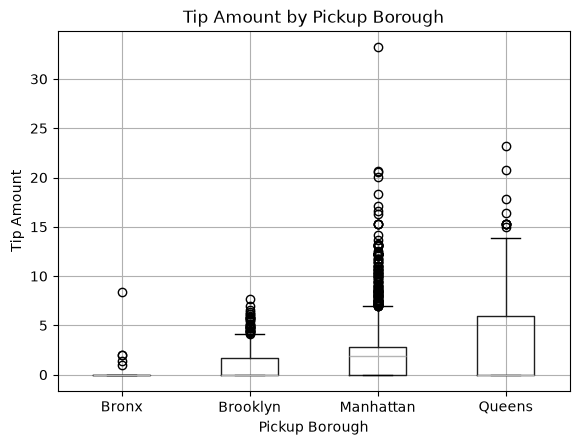

In [18]:
plt.figure(figsize=(10, 6))

df.boxplot(column='tip', by='pickup_borough')

plt.title('Tip Amount by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Tip Amount')

plt.suptitle('')
plt.show()


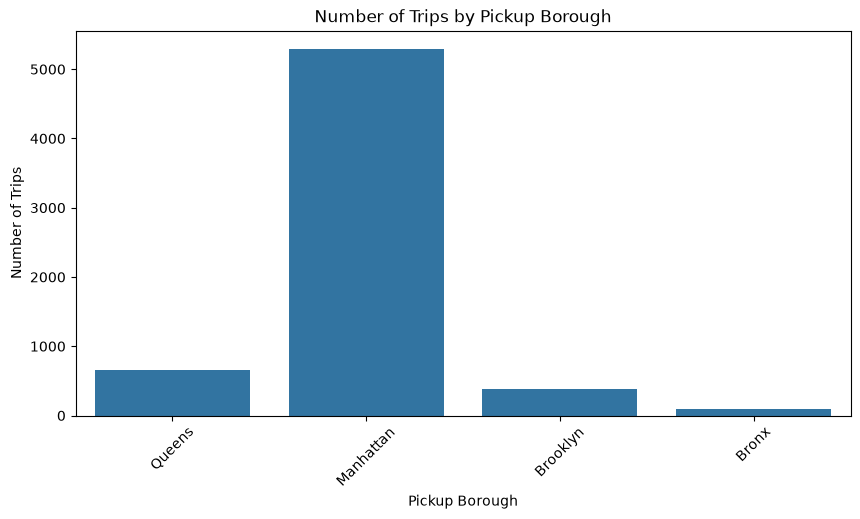

In [19]:
plt.figure(figsize=(10, 5))

sns.countplot(data=df, x='pickup_borough')

plt.title('Number of Trips by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Number of Trips')

plt.xticks(rotation=45)
plt.show()

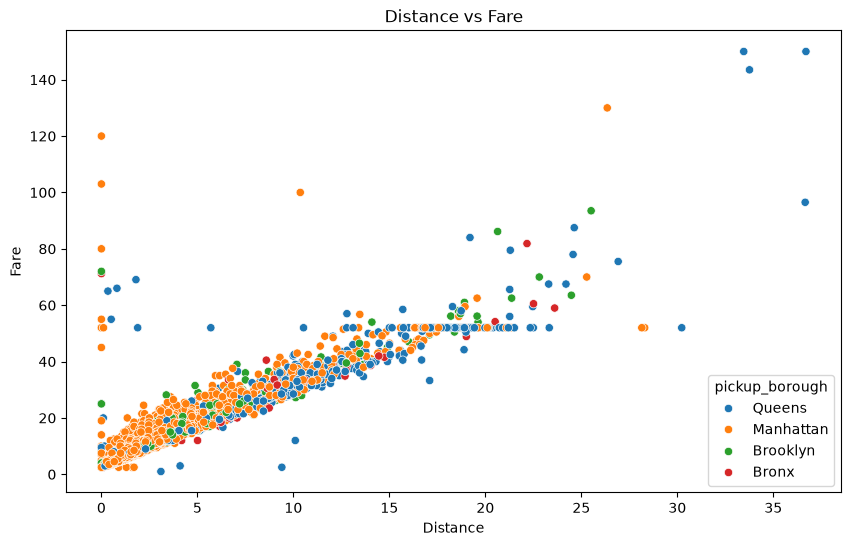

In [20]:
plt.figure(figsize=(10, 6))

sns.scatterplot(data=df, x='distance', y='fare',
                hue='pickup_borough')

plt.title('Distance vs Fare')
plt.xlabel('Distance')
plt.ylabel('Fare')

plt.show()

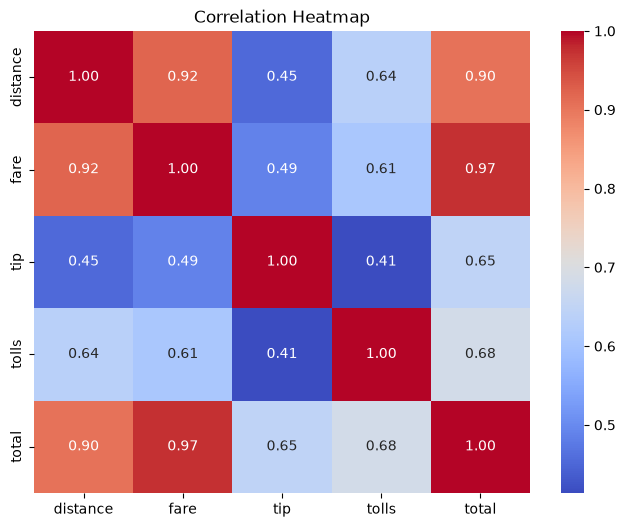

In [21]:
# Create heatmap
numeric_df = df[['distance', 'fare', 'tip', 'tolls', 'total']]

correlation = numeric_df.corr()

plt.figure(figsize=(8, 6))

sns.heatmap(correlation, annot=True, cmap='coolwarm',
            fmt='.2f')

plt.title('Correlation Heatmap')
plt.show()

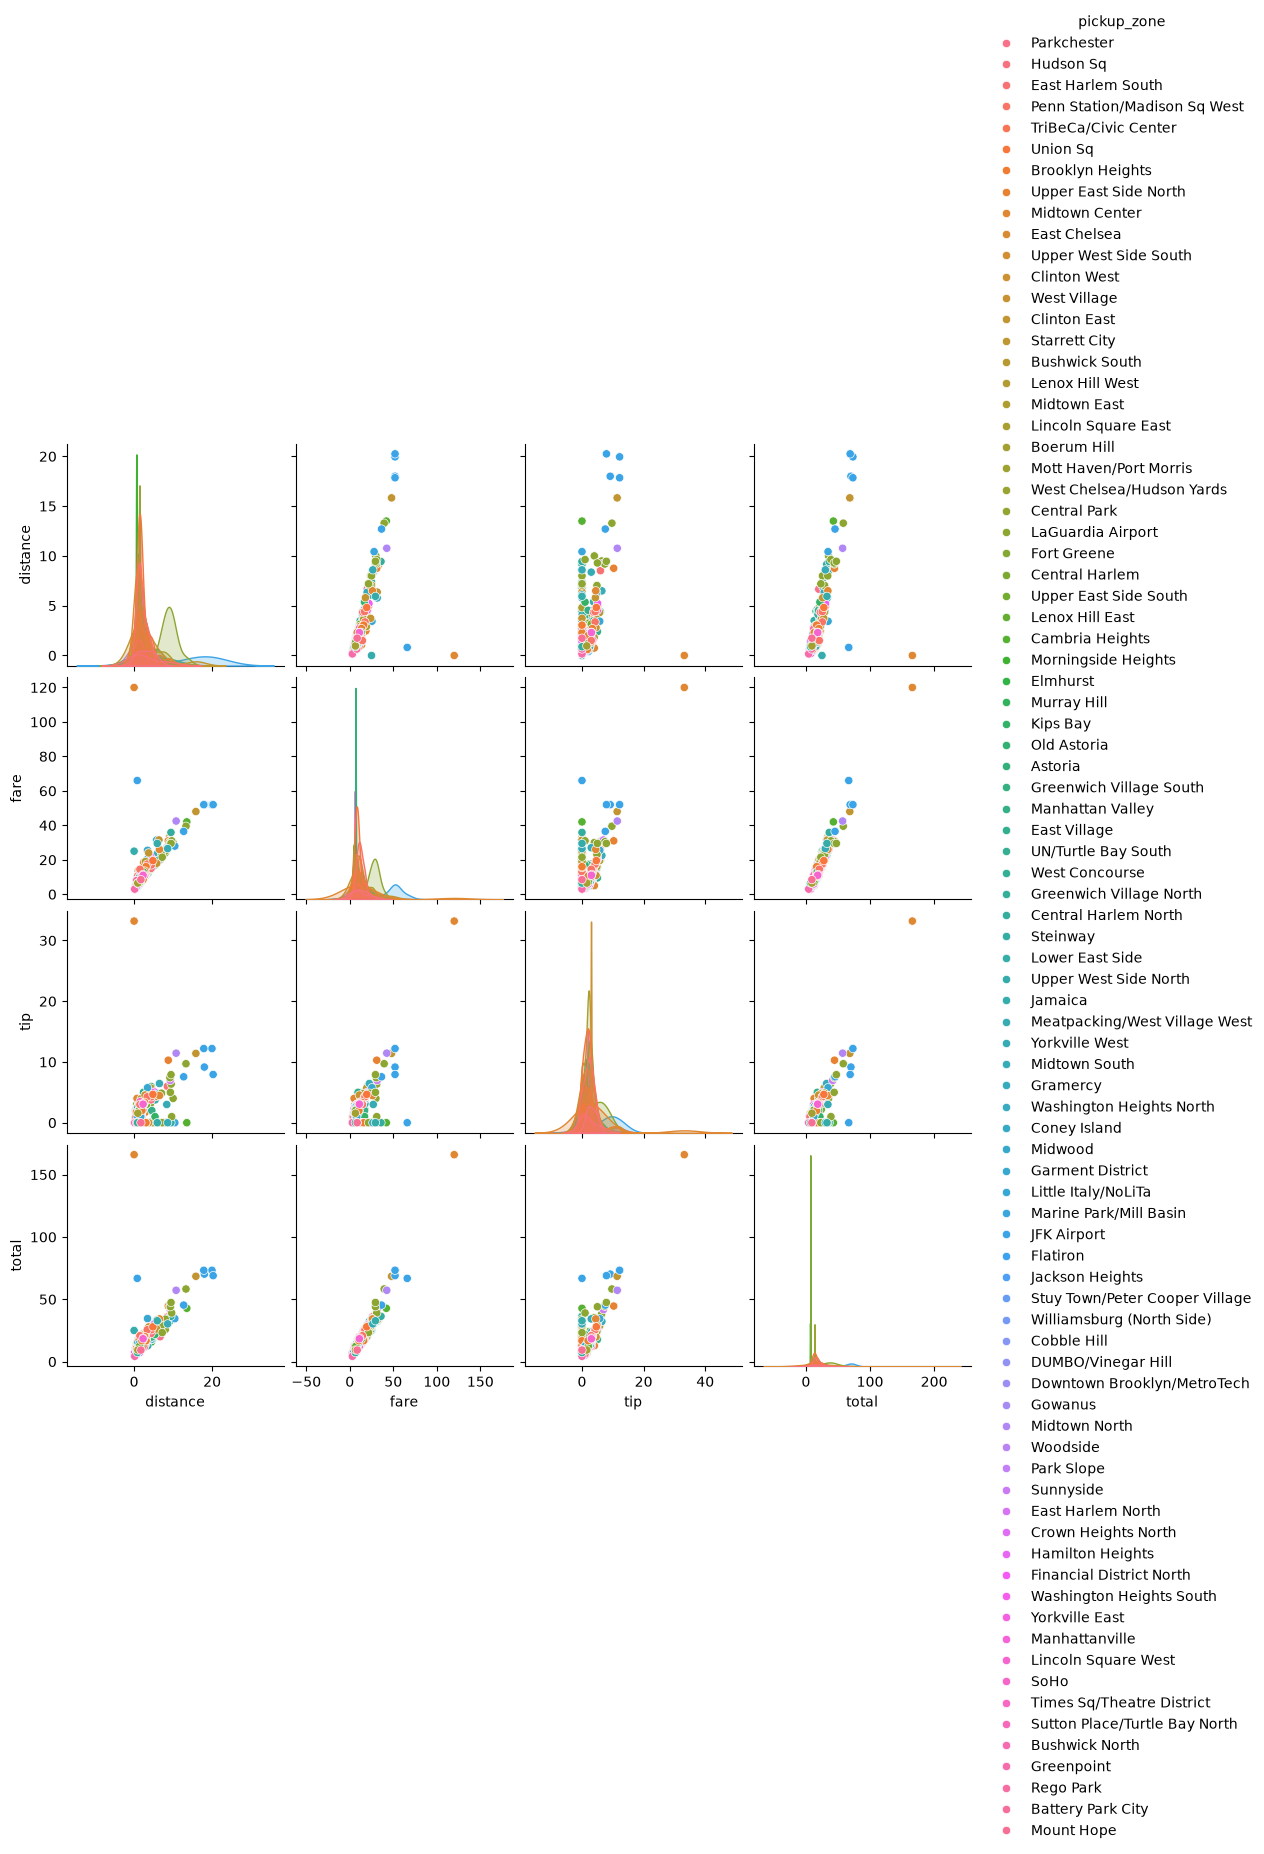

In [25]:
pair_data = df[['distance', 'fare', 'tip', 'total', 'pickup_zone']]


pair_data = pair_data.dropna().sample(
    n=min(300, len(pair_data)), random_state=42
)

sns.pairplot(pair_data, hue='pickup_zone')

plt.show()

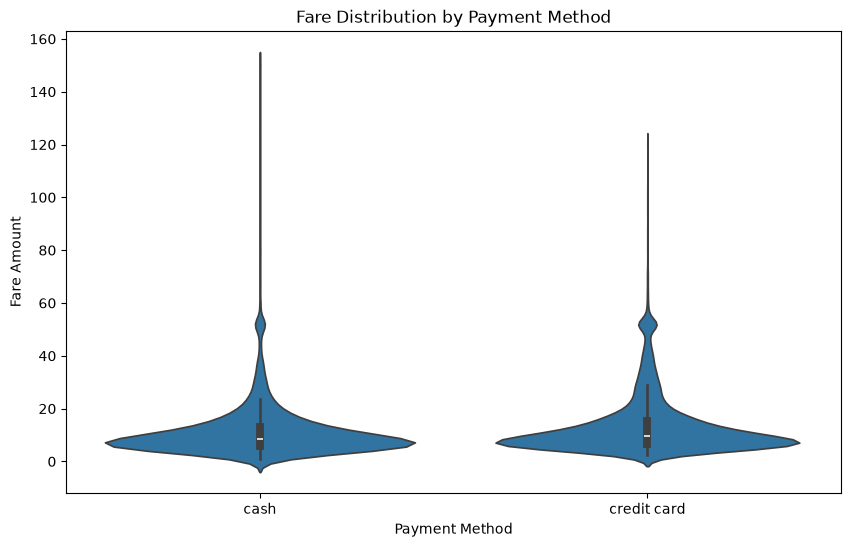

In [26]:
plt.figure(figsize=(10, 6))

sns.violinplot(data=df, x='payment', y='fare')

plt.title('Fare Distribution by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Fare Amount')

plt.show()